# NYC weather-based spread signal: gross backtest
## tl;dr
**We tested an actual directional trading rule—but did not establish convincing gross alpha.** The validation-selected **linear forecast-temperature spread rule** earned a hypothetical **+$1,020.96** in 2025, versus **+$321.98** for calendar-only and **+$1,384.92** for always virtual load / the training-mean benchmark. Each active day assumes one MWh clears; no costs or executable fills are modeled.

The selected rule's seven-day block-bootstrap interval for mean daily gross payoff spans **−$8.10 to +$18.29**. Its incremental interval versus calendar spans **−$0.72 to +$6.04/day**. Neither establishes a reliably positive effect in this year. The best day earned **$1,768.53**, exceeding the entire net profit; the other 361 days together lost **$747.57**.

A spline did better in 2025, but performed much worse in validation and was **not selected**. Promoting it after seeing the final year would be a different, outcome-informed experiment. The prior **16.6% day-ahead price MAE improvement remains valid for that separate question**; it was never a trading return.

## Context & Methods
At 04:00 New York time on D−1, predict the NYC hour-18 **real-time minus day-ahead spread** for D. Positive predicted spread → virtual load (+1); negative → virtual supply (−1); exactly zero → flat. For a one-MWh cleared schedule, gross energy payoff is **side × (RT − DA)** dollars.

This is the first trading-rule experiment following the demand and DA-price studies. **Neither previous fitted model is an input.** We refit spread models directly using the same verified calendar and archived forecast-temperature covariates. Train 2021–2023, select linear vs three-hinge spline on **2024 gross mean daily payoff**, refit 2021–2024, evaluate 2025. All models share fourteen calendar controls. No threshold/size search, price-history features or realized future weather.

### Key Assumptions
- One MWh is assumed cleared per active signal. Actual bid acceptance, limits, partial fills and access are not established.
- Fees, uplift, slippage, collateral/financing and other charges are intentionally excluded. This is hypothetical gross energy settlement, not net trading profitability or a capital-based percentage return.
- Both DA and RT prices are unknown at cutoff and are outcomes only. Corrected historical labels and archive timestamp evidence do not reconstruct exact historical training/invoice vintages.
- 2025 was already examined in prior demand/DA-price research; this is retrospective chronological evaluation, not a blind or prospective test.
- Selectively excluded forecast dates are shared by every strategy. One final year and heavy tails limit inference.

The frozen choices are in [EXPERIMENT.md](EXPERIMENT.md). Market mechanics and source evidence are in the [feasibility brief](../trading_feasibility/FEASIBILITY_BRIEF.md).

### 1. Reproduce the fixed experiment

In [1]:
from pathlib import Path
import sys,json,io,contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display
ROOT=Path.cwd()
assert (ROOT/'EXPERIMENT.md').exists(), 'Execute from spread_backtest.'
sys.path.insert(0,str(ROOT/'src'))
from run import main
with contextlib.redirect_stdout(io.StringIO()):
    main()  # Source verification, chronological selection, refit, gross payoff arithmetic.
OUT=ROOT/'outputs'
summary=json.loads((OUT/'summary.json').read_text())
selected=summary['selected_weather_strategy']
LABELS={'calendar':'Calendar rule','linear':'Linear-weather rule','spline':'Spline-weather rule',
        'always_load':'Always virtual load','always_supply':'Always virtual supply','flat':'Flat',
        'training_mean':'Training-mean rule'}
plt.rcParams.update({'figure.figsize':(10,5),'font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,
                     'axes.axisbelow':True,'savefig.dpi':150})
def save(fig,name):
    fig.tight_layout();fig.savefig(OUT/name,bbox_inches='tight');plt.show()
print('Same frozen gross experiment reproduced. Selected:',selected)

Same frozen gross experiment reproduced. Selected: linear


## Data
NYISO NYC / Zone J PTID 61761, delivery 18:00–19:00. [Day-ahead zonal prices](https://mis.nyiso.com/public/P-2Alist.htm) and [official integrated real-time zonal prices](https://mis.nyiso.com/public/P-4Alist.htm) exist for all 1,826 dates in 2021–2025. The official RT series preserves interval-duration weighting; no unweighted five-minute average is substituted. Both outcome prices already include their loss/congestion components.

The prior HRRR forecast gate leaves 1,809 eligible dates: 360/359/364/364/362 by year. Seventeen late or insufficiently timestamped files remain excluded. Forecast inputs were retained before cutoff with a five-minute buffer; issue/valid metadata were verified. No price values enter features.

In [2]:
eligible=pd.read_csv(OUT/'eligible_data.csv')
display(eligible.groupby('year').size().rename('Eligible target days').to_frame())
assert (pd.to_datetime(eligible.archive_available_utc,utc=True)
        <= pd.to_datetime(eligible.cutoff_utc,utc=True)-pd.Timedelta(minutes=5)).all()
print('Every included forecast precedes the frozen cutoff buffer.')
validation=pd.read_csv(OUT/'validation_metrics.csv')
display(validation[['strategy','active_trades','total_gross_dollars','mean_daily_gross_dollars']].round(3))

,Eligible target days
year,
2021,360
2022,359
2023,364
2024,364
2025,362


Every included forecast precedes the frozen cutoff buffer.


,strategy,active_trades,total_gross_dollars,mean_daily_gross_dollars
0,calendar,364,1728.42,4.748
1,linear,364,1647.22,4.525
2,spline,364,323.42,0.889
3,always_load,364,540.38,1.485
4,always_supply,364,-540.38,-1.485
5,flat,0,0.00,0.000
6,training_mean,364,540.38,1.485


The linear weather rule earned $4.53/day in 2024 versus $0.89/day for the spline; it was selected under the prespecified trading objective. Calendar-only earned $4.75/day in validation. The trading objective deliberately differs from the prior DA-price study's MAE objective.

## Results
### 2. Gross payoff and risk versus benchmarks

,active_trades,virtual_load_days,virtual_supply_days,total_gross_dollars,mean_daily_gross_dollars,win_rate_active,daily_std_dollars,max_drawdown_dollars,worst_day_dollars
strategy,,,,,,,,,
calendar,362,191,171,321.98,0.889,0.428,113.666,1660.66,-302.82
linear,362,195,167,1020.96,2.820,0.445,113.634,983.09,-233.70
spline,362,184,178,2524.12,6.973,0.508,113.455,1300.91,-302.82
always_load,362,362,0,1384.92,3.826,0.331,113.605,1096.67,-233.70
always_supply,362,0,362,-1384.92,-3.826,0.669,113.605,2684.56,-1768.53
flat,0,0,0,0.00,0.000,NaN,0.000,0.00,-0.00
training_mean,362,362,0,1384.92,3.826,0.331,113.605,1096.67,-233.70


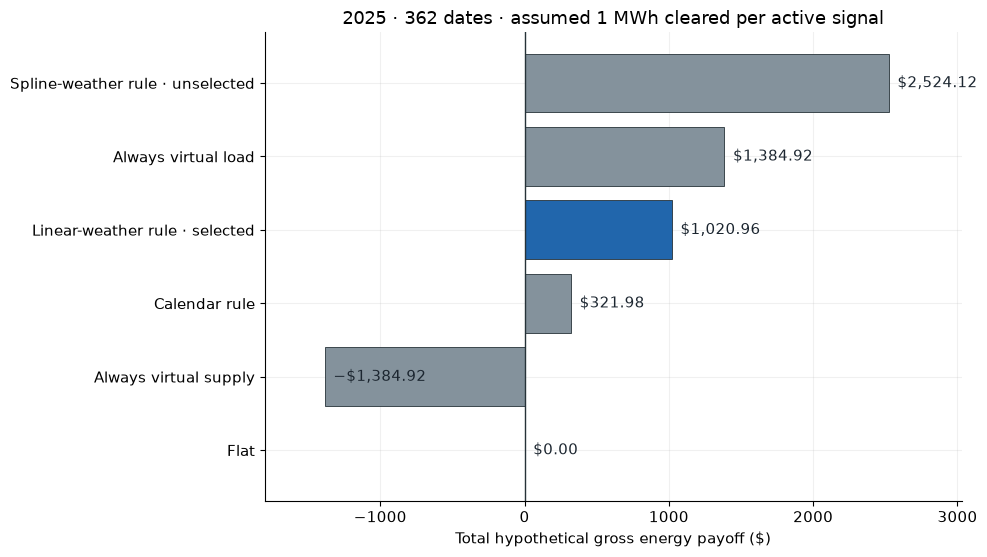

In [3]:
metrics=pd.read_csv(OUT/'test_metrics.csv')
overall=metrics.loc[metrics.group_type.eq('overall')].set_index('strategy')
display(overall[['active_trades','virtual_load_days','virtual_supply_days','total_gross_dollars',
                 'mean_daily_gross_dollars','win_rate_active','daily_std_dollars',
                 'max_drawdown_dollars','worst_day_dollars']].round(3))
fig,ax=plt.subplots(figsize=(10,5.7))
order=['flat','always_supply','calendar','linear','always_load','spline']
values=overall.loc[order,'total_gross_dollars']
colors=['#2166ac' if name==selected else '#84929c' for name in order]
bars=ax.barh([LABELS[name]+(' · selected' if name==selected else ' · unselected' if name=='spline' else '') for name in order],values,color=colors,
             edgecolor='#263238',linewidth=.6)
ax.axvline(0,color='#263238',linewidth=1)
for rect,value in zip(bars,values):
    label=f'−${abs(value):,.2f}' if value<0 else f'${value:,.2f}'
    ax.text(value+60,rect.get_y()+rect.get_height()/2,label,ha='left',va='center',color='#1c2630')
ax.set(xlabel='Total hypothetical gross energy payoff ($)',title='2025 · 362 dates · assumed 1 MWh cleared per active signal')
ax.set_xlim(values.min()*1.30,values.max()*1.20)
save(fig,'01_gross_benchmark_comparison.png')

**The selected weather rule loses the benchmark comparison to always virtual load / training mean.** Its +$698.98 increment over calendar is positive in the sample, but statistically uncertain. The always-supply strategy wins more often (66.9%) yet loses $1,384.92 because a few large adverse spreads outweigh its frequent small wins. Win rate is not profitability.

The spline's +$2,524.12 is an explicitly reported unselected alternative. It cannot replace the primary linear rule after seeing 2025. No strategy has been retuned.

### 3. Cumulative dollar payoff and drawdown

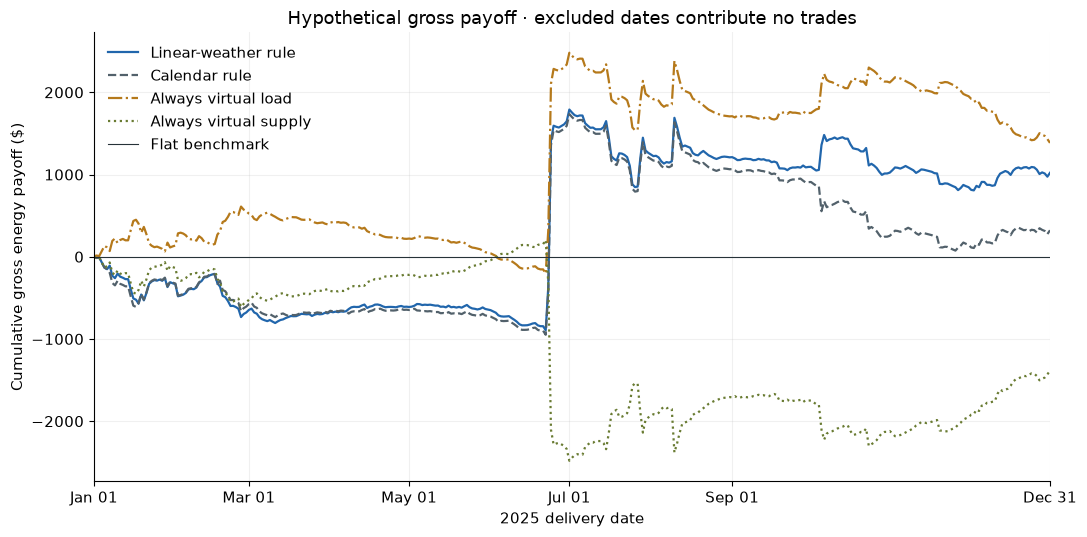

In [4]:
signals=pd.read_csv(OUT/'test_daily_signals.csv',parse_dates=['delivery_date'])
full=signals.set_index('delivery_date').reindex(pd.date_range('2025-01-01','2025-12-31'))
fig,ax=plt.subplots(figsize=(11,5.5))
for name,color,style in [(selected,'#2166ac','-'),('calendar','#52616b','--'),
                         ('always_load','#b5791b','-.'),('always_supply','#697b32',':')]:
    equity=full[name+'_pnl'].fillna(0).cumsum()
    ax.plot(equity.index,equity,label=LABELS[name],color=color,linestyle=style,linewidth=1.6)
ax.axhline(0,color='#263238',linewidth=.8,label='Flat benchmark')
ax.set(xlabel='2025 delivery date',ylabel='Cumulative gross energy payoff ($)',
       title='Hypothetical gross payoff · excluded dates contribute no trades')
ax.set_xticks(pd.to_datetime(['2025-01-01','2025-03-01','2025-05-01','2025-07-01','2025-09-01','2025-12-31']))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax.set_xlim(pd.Timestamp('2025-01-01'),pd.Timestamp('2025-12-31'))
ax.legend(frameon=False)
save(fig,'02_cumulative_gross_payoff.png')

The selected rule's maximum drawdown is **$983.09**, against $1,020.96 net gross gain. It takes virtual load on 195 days and virtual supply on 167, differing from calendar on 32 days. The training-mean rule chooses virtual load using fitting data and therefore duplicates that constant-direction benchmark in this evaluation.

### 4. Monthly stability

,month,days,total_gross_dollars,mean_daily_gross_dollars
8,1,31,-322.94,-10.417
15,2,28,-354.93,-12.676
22,3,31,-11.06,-0.357
29,4,30,81.50,2.717
36,5,31,-34.32,-1.107
43,6,29,2289.69,78.955
50,7,31,-382.94,-12.353
57,8,31,-55.64,-1.795
64,9,30,-116.96,-3.899
71,10,29,-69.05,-2.381


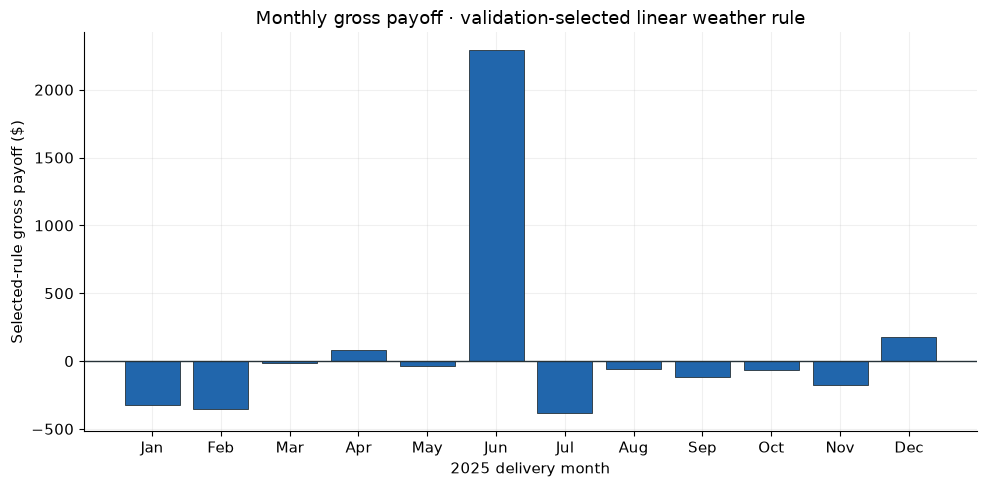

In [5]:
monthly=metrics.loc[metrics.group_type.eq('month') & metrics.strategy.eq(selected)].copy()
monthly['month']=monthly['group'].astype(int);monthly=monthly.sort_values('month')
display(monthly[['month','days','total_gross_dollars','mean_daily_gross_dollars']].round(3))
fig,ax=plt.subplots()
ax.bar([pd.Timestamp(2025,m,1).strftime('%b') for m in monthly.month],monthly.total_gross_dollars,
       color='#2166ac',edgecolor='#263238',linewidth=.6)
ax.axhline(0,color='#263238',linewidth=1)
ax.set(xlabel='2025 delivery month',ylabel='Selected-rule gross payoff ($)',
       title='Monthly gross payoff · validation-selected linear weather rule')
save(fig,'03_monthly_gross_payoff.png')

Only **three months** have positive net payoff; June contributes $2,289.69. A positive full-year total masks weak consistency. No months are removed or used to redesign the rule.

### 5. Paired uncertainty in the gross edge

,selected_weather,benchmark,block_days,mean_incremental_daily_dollars,lower_95_dollars,upper_95_dollars,paired_days
0,linear,flat,7,2.820,-8.100,18.292,362
1,linear,flat,14,2.820,-8.104,19.300,362
2,linear,flat,28,2.820,-6.884,18.012,362
3,linear,calendar,7,1.931,-0.725,6.039,362
4,linear,calendar,14,1.931,-0.630,5.791,362
5,linear,calendar,28,1.931,-0.513,5.767,362
6,linear,always_load,7,-1.005,-8.073,5.863,362
7,linear,always_load,14,-1.005,-8.088,5.548,362
8,linear,always_load,28,-1.005,-7.600,5.455,362
9,linear,always_supply,7,6.646,-12.926,36.626,362


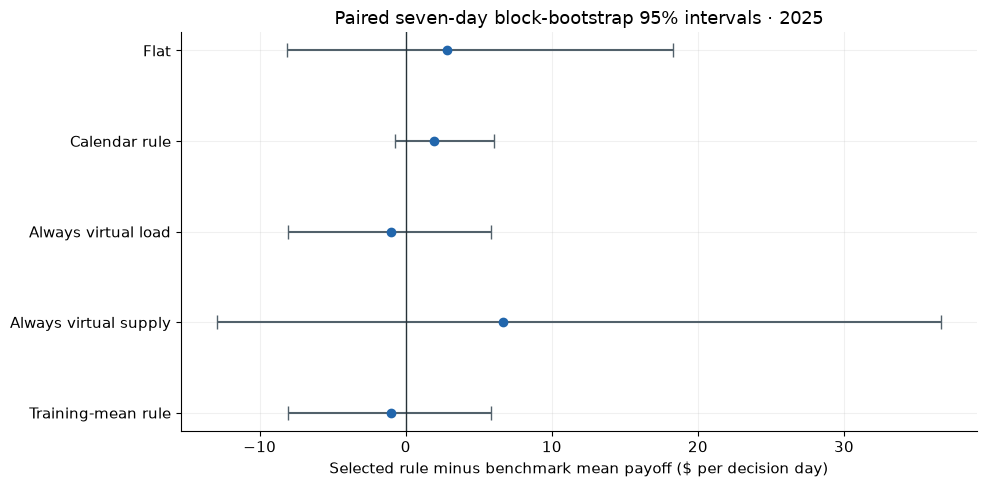

In [6]:
intervals=pd.read_csv(OUT/'uncertainty.csv')
display(intervals.round(3))
primary=intervals.loc[intervals.block_days.eq(7)].copy()
fig,ax=plt.subplots(figsize=(10,5))
y=np.arange(len(primary))
ax.errorbar(primary.mean_incremental_daily_dollars,y,
            xerr=[primary.mean_incremental_daily_dollars-primary.lower_95_dollars,
                  primary.upper_95_dollars-primary.mean_incremental_daily_dollars],
            fmt='o',color='#2166ac',ecolor='#52616b',capsize=5,linewidth=1.5)
ax.axvline(0,color='#263238',linewidth=1)
ax.set_yticks(y,[LABELS[name] for name in primary.benchmark])
ax.invert_yaxis()
ax.set(xlabel='Selected rule minus benchmark mean payoff ($ per decision day)',
       title='Paired seven-day block-bootstrap 95% intervals · 2025')
save(fig,'04_paired_gross_uncertainty.png')

The intervals cross zero for raw payoff versus flat and for every incremental comparison, including calendar and always-load. The 14/28-day sensitivity intervals also cross zero. **Reliable positive gross alpha is not established**, even before costs. Bootstrap intervals cover this year's dependent payoffs, not refitting uncertainty or every future year.

### 6. Large-spread reconciliation and concentration

In [7]:
best=pd.read_csv(OUT/'ten_best_days.csv');worst=pd.read_csv(OUT/'ten_worst_days.csv')
columns=['delivery_date','finalized_price_mwh','rt_integrated_price_mwh','rt_minus_da_mwh',selected+'_side',selected+'_pnl']
display(best[columns].round(3));display(worst[columns].round(3))
print('Ten best days together:',round(best[selected+'_pnl'].sum(),2),'dollars.')
display(pd.read_csv(OUT/'residual_diagnostics.csv').round(3))

,delivery_date,finalized_price_mwh,rt_integrated_price_mwh,rt_minus_da_mwh,linear_side,linear_pnl
0,2025-06-24,365.00,2133.53,1768.53,1,1768.53
1,2025-06-23,300.20,837.41,537.21,1,537.21
2,2025-08-10,97.28,626.09,528.81,1,528.81
3,2025-07-28,268.49,608.97,340.48,1,340.48
4,2025-10-05,93.93,396.75,302.82,1,302.82
5,2025-07-29,386.73,640.64,253.91,1,253.91
6,2025-06-25,268.15,450.60,182.45,1,182.45
7,2025-07-01,120.29,262.82,142.53,1,142.53
8,2025-10-06,122.00,243.76,121.76,1,121.76
9,2025-01-19,284.91,174.50,-110.41,-1,110.41


,delivery_date,finalized_price_mwh,rt_integrated_price_mwh,rt_minus_da_mwh,linear_side,linear_pnl
0,2025-07-17,292.09,58.39,-233.70,1,-233.70
1,2025-07-25,300.00,73.82,-226.18,1,-226.18
2,2025-10-23,79.19,291.35,212.16,-1,-212.16
3,2025-07-16,255.09,61.04,-194.05,1,-194.05
4,2025-07-30,340.51,185.46,-155.05,1,-155.05
5,2025-02-02,109.82,257.57,147.75,-1,-147.75
6,2025-08-12,239.07,107.26,-131.81,1,-131.81
7,2025-11-19,88.97,215.81,126.84,-1,-126.84
8,2025-01-08,185.82,309.89,124.07,-1,-124.07
9,2025-01-15,173.03,294.98,121.95,-1,-121.95


Ten best days together: 4288.91 dollars.


,model,lag_days,correlation,pairs
0,calendar,1,0.304,358
1,calendar,7,0.061,352
2,linear,1,0.301,358
3,linear,7,0.061,352
4,spline,1,0.279,358
5,spline,7,0.059,352


The largest gain is **June 24, 2025**: official archived NYC DA price **$365.00/MWh**, integrated RT price **$2,133.53/MWh**, and spread **+$1,768.53/MWh**. These exact values were reconciled to the two raw ZIP members; the large observation is retained. The selected rule, calendar and always-load all took virtual load that day, so it is not evidence of unique weather timing.

The best day exceeds the selected rule's entire net total: the remaining 361 dates sum to **−$747.57**. The ten best days sum to $4,288.91, or 420.1% of net gain; percentages above 100% mean other days offset the winners. This is a concentration diagnostic, not an alternative backtest with outliers removed.

## Takeaways
**We have now tested a genuine directional spread signal in a hypothetical gross backtest. We have not demonstrated convincing alpha.** Positive sample P&L is outweighed by weak benchmark performance, broad uncertainty, concentration in a few large events and only one exposed evaluation year. Costs were not needed to reach this limited conclusion.

The earlier 39.2% demand and 16.6% DA-price error reductions remain findings about their own questions. They do not imply tradable spread skill. The primary linear-weather signal was selected using validation trading payoff; switching to the final-year-winning spline now would be a new, outcome-informed choice requiring fresh evaluation.

Stop this fixed experiment here. No threshold search, sizing optimization, execution extension or cost model has been started. Keep the negative/uncertain trading result alongside the useful earlier research rather than presenting the price-error result as a profitable strategy.

Reproduce from this folder: use the parent `price_research/.venv` environment or install this folder's `requirements.txt`, then `python src/run.py`, `python -m unittest discover -s tests -v`, and `python execute_notebook.py`. Earlier raw inputs and their receipts remain required in adjacent project folders. This notebook reruns source verification, fitting, selection and the same frozen evaluation.